# Parcial 2 - Ejercicio 2: Aprendizaje por refuerzo con el juego **Pong Hau K'i**

## Registro del juego (para la planilla)

| Campo | Texto |
|---|---|
| **Juego** | Pong Hau K'i (juego chino de bloqueo, 5 casillas) |
| **Descripción** | Juego de mesa tradicional chino para dos jugadores en un tablero de solo 5 puntos (4 esquinas y un centro) unidos por líneas. Cada jugador tiene 2 fichas y siempre queda un único punto vacío. En su turno, el jugador mueve una de sus fichas al punto vacío, siempre que esté unido por una línea. Pierde quien en su turno no puede mover (queda bloqueado). Si pasan 20 movimientos sin que nadie quede bloqueado, es empate. Se implementa con aprendizaje por refuerzo tabular (función de valor), igual que el tres en raya de clase. |

**¿Por qué este juego?**
- Es **muy sencillo**: 5 casillas, 4 fichas y como mucho 2 movimientos posibles por turno. Solo existen **30 posiciones distintas** del tablero (el tres en raya tiene miles), así que la tabla de la función de valor es pequeña y se puede mostrar completa.
- Es de tablero y por turnos, **como el tres en raya**, así que se puede usar el mismo código visto en clase.
- **No se parece** a los juegos ya registrados: no se colocan fichas para formar líneas (Conecta 4, SOS, Juego de 15), no se capturan piezas (Hexapeón), no se retiran objetos (Nim, Chomp) y no hay dados ni azar (Mini Cacho, Shut the box). Las fichas **se deslizan** por un tablero en forma de grafo, que es una mecánica distinta.

## 1. Reglas y tablero

```
 X(1)         X(2)        Puntos: 1 y 2 arriba, 3 al centro, 4 y 5 abajo.
  |  \       /  |
  |    \   /    |         Líneas: 1-3, 2-3, 4-3, 5-3 (diagonales al centro),
  |     ·(3)    |                 1-4 y 2-5 (lados) y 4-5 (abajo).
  |    /   \    |
  |  /       \  |         ¡Entre 1 y 2 NO hay línea!
 O(4)---------O(5)
```

- Inicio: **X** tiene las fichas en 1 y 2, **O** en 4 y 5, y el centro (3) está vacío. Empieza X.
- Como siempre hay **un solo punto vacío**, una jugada consiste en elegir **cuál ficha** propia se mueve a ese punto (debe estar unida con una línea).
- **Gana** quien deja al rival sin movimientos. Ejemplo: si el vacío es el punto 1, solo se puede llegar desde 3 o 4; si esos dos puntos son de X y le toca a O, O pierde.
- **Empate** si se llega a 20 movimientos (10 por jugador). En el juego real, dos jugadores que no se equivocan pueden mover para siempre; este límite evita partidas infinitas.

## 2. ¿Cómo se aplica el aprendizaje por refuerzo?

Es exactamente el mismo método del cuadernillo de clase del tres en raya:

| Concepto | En este juego |
|---|---|
| **Agente** | El jugador que aprende (uno para X y otro para O) |
| **Entorno** | El tablero y las reglas (clase `Board`) |
| **Estado** | La posición de las fichas: un vector de 5 números, `1` = X, `-1` = O, `0` = vacío. Ej: `[1 1 0 -1 -1]` es el inicio |
| **Acción** | Cuál de mis fichas muevo al punto vacío |
| **Recompensa** | Solo al final: **1** si gana, **0.5** si empata, **0** si pierde |
| **Función de valor V(s)** | Un diccionario `estado -> valor` que estima la probabilidad de ganar desde ese estado |

**Cómo juega el agente** (exploración vs explotación):
- Con probabilidad `prob_exp` hace una jugada **al azar** (explora, para descubrir posiciones nuevas).
- Si no, prueba cada jugada posible, mira el **valor del estado al que llegaría** y elige la de **mayor valor** (explota lo aprendido).

**Cómo aprende** (al terminar cada partida): recorre las posiciones que **él mismo** generó, desde la última hacia la primera, y actualiza

$$V(s) \leftarrow V(s) + \alpha \, \big(r - V(s)\big)$$

donde `r` empieza siendo la recompensa final y luego pasa a ser el valor recién actualizado del estado siguiente. Así el premio (o castigo) del final se va **propagando hacia atrás** a las jugadas que llevaron a él. `α` (alpha) es la tasa de aprendizaje: cuánto cambio el valor con cada partida.

**Única diferencia con el tres en raya de clase:** en el tres en raya, mirando el tablero se sabe de quién es el turno (contando X y O). Aquí **no**: siempre hay 2 X y 2 O. Por eso cada agente guarda en su tabla **solo las posiciones que él dejó después de su jugada**, para no mezclar "posición donde me toca a mí" con "posición donde le toca al rival".

## 3. Código

### 3.1 Librerías

In [1]:
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# Semilla fija para que los resultados se puedan repetir
np.random.seed(42)

### 3.2 El tablero (entorno)

`VECINOS` describe las líneas del tablero: para cada punto, desde qué puntos se puede llegar. Los puntos se numeran 0 a 4 en el código (1 a 5 para el humano).

In [2]:
VECINOS = {0: [2, 3], 1: [2, 4], 2: [0, 1, 3, 4], 3: [0, 2, 4], 4: [1, 2, 3]}
MAX_MOVIMIENTOS = 20


class Board():
    def __init__(self):
        self.reset()

    def reset(self):
        # X (1) arriba, O (-1) abajo, centro vacío; empieza X
        self.state = np.array([1, 1, 0, -1, -1])
        self.turno = 1
        self.movimientos = 0

    def valid_moves(self, symbol):
        # una jugada es (origen, destino): mover una ficha propia vecina al único punto vacío
        vacio = int(np.where(self.state == 0)[0][0])
        return [(origen, vacio) for origen in VECINOS[vacio] if self.state[origen] == symbol]

    def update(self, symbol, origen, destino):
        if (origen, destino) not in self.valid_moves(symbol):
            raise ValueError('movimiento ilegal !')
        self.state[destino] = symbol
        self.state[origen] = 0
        self.turno = -symbol
        self.movimientos += 1

    def is_game_over(self):
        # el jugador al que le toca y no puede mover pierde: gana el otro
        if len(self.valid_moves(self.turno)) == 0:
            return -self.turno
        # empate por límite de movimientos
        if self.movimientos >= MAX_MOVIMIENTOS:
            return 0
        # seguir jugando
        return None

In [3]:
def dibujar_tablero(board):
    f = [{1: 'X', -1: 'O', 0: '·'}[int(v)] for v in board.state]
    print(f' {f[0]}(1)         {f[1]}(2)')
    print('  |  \\       /  |')
    print('  |    \\   /    |')
    print(f'  |     {f[2]}(3)    |')
    print('  |    /   \\    |')
    print('  |  /       \\  |')
    print(f' {f[3]}(4)---------{f[4]}(5)')
    print()


board = Board()
dibujar_tablero(board)
print('Jugadas válidas de X al inicio (origen, destino):', board.valid_moves(1))

 X(1)         X(2)
  |  \       /  |
  |    \   /    |
  |     ·(3)    |
  |    /   \    |
  |  /       \  |
 O(4)---------O(5)

Jugadas válidas de X al inicio (origen, destino): [(0, 2), (1, 2)]


**Todos los estados posibles.** Hay 5 puntos: se eligen 2 para X, 2 para O y 1 queda vacío: $\frac{5!}{2!\,2!\,1!} = 30$ posiciones. Un ejemplo de derrota: si le toca a O, el vacío está en el punto 1 y X ocupa 3 y 4, O no puede mover.

In [4]:
from itertools import permutations

todos_los_estados = sorted(set(permutations([1, 1, -1, -1, 0])))
print('Cantidad de posiciones posibles:', len(todos_los_estados))

ejemplo = Board()
ejemplo.state = np.array([0, -1, 1, 1, -1])
ejemplo.turno = -1
dibujar_tablero(ejemplo)
print('Jugadas de O:', ejemplo.valid_moves(-1), '-> ganador:', 'X' if ejemplo.is_game_over() == 1 else ejemplo.is_game_over())

Cantidad de posiciones posibles: 30
 ·(1)         O(2)
  |  \       /  |
  |    \   /    |
  |     X(3)    |
  |    /   \    |
  |  /       \  |
 X(4)---------O(5)

Jugadas de O: [] -> ganador: X


### 3.3 La partida entre dos jugadores y la recompensa

Igual que en clase: `Game` hace jugar a dos agentes entre sí (*self-play*), y al final de cada partida reparte la recompensa: 1 al que gana, 0 al que pierde y 0.5 a ambos si empatan.

In [5]:
class Game():
    def __init__(self, player1, player2):
        player1.symbol = 1
        player2.symbol = -1
        self.players = [player1, player2]
        self.board = Board()

    def selfplay(self, rounds=100):
        wins = [0, 0]
        for i in range(rounds):
            self.board.reset()
            for player in self.players:
                player.reset()
            game_over = False
            while not game_over:
                for player in self.players:
                    origen, destino = player.move(self.board)
                    self.board.update(player.symbol, origen, destino)
                    # solo el que movió guarda la posición que dejó
                    player.update(self.board)
                    if self.board.is_game_over() is not None:
                        game_over = True
                        break
            self.reward()
            for ix, player in enumerate(self.players):
                if self.board.is_game_over() == player.symbol:
                    wins[ix] += 1
        return wins

    def reward(self):
        winner = self.board.is_game_over()
        if winner == 0:  # empate
            for player in self.players:
                player.reward(0.5)
        else:  # 1 al que gana, 0 al que pierde
            for player in self.players:
                if winner == player.symbol:
                    player.reward(1)
                else:
                    player.reward(0)

### 3.4 El agente (función de valor)

Es la clase `Agent` de clase, con dos cambios mínimos: la jugada es `(origen, destino)` en vez de `(fila, columna)`, y el estado es el vector de 5 puntos en vez de la matriz de 3 x 3.

In [6]:
class Agent():
    def __init__(self, alpha=0.1, prob_exp=0.5):
        self.value_function = {}  # tabla con pares estado -> valor
        self.alpha = alpha        # tasa de aprendizaje
        self.positions = []       # posiciones que dejó el agente en la partida actual
        self.prob_exp = prob_exp  # probabilidad de explorar

    def reset(self):
        self.positions = []

    def move(self, board, explore=True):
        valid_moves = board.valid_moves(self.symbol)
        # exploración: jugada al azar
        if explore and np.random.uniform(0, 1) < self.prob_exp:
            ix = np.random.choice(len(valid_moves))
            return valid_moves[ix]
        # explotación: la jugada que lleva al estado con más valor
        max_value = -1000
        for origen, destino in valid_moves:
            next_board = board.state.copy()
            next_board[destino] = self.symbol
            next_board[origen] = 0
            value = self.value_function.get(str(next_board), 0)
            if value >= max_value:
                max_value = value
                mejor = (origen, destino)
        return mejor

    def update(self, board):
        self.positions.append(str(board.state))

    def reward(self, reward):
        # al final de la partida se actualizan los estados de atrás hacia adelante
        for p in reversed(self.positions):
            if self.value_function.get(p) is None:
                self.value_function[p] = 0
            self.value_function[p] += self.alpha * (reward - self.value_function[p])
            reward = self.value_function[p]

### 3.5 Un rival aleatorio y la función para evaluar

Para medir si el agente aprendió, lo hago jugar **sin explorar** (`explore=False`) contra un jugador que mueve **al azar**, y cuento victorias, empates y derrotas.

In [7]:
class Aleatorio():
    def reset(self):
        pass

    def move(self, board, explore=True):
        jugadas = board.valid_moves(self.symbol)
        return jugadas[np.random.choice(len(jugadas))]

    def update(self, board):
        pass

    def reward(self, reward):
        pass


def evaluar(jugador, rival, simbolo_jugador=1, partidas=1000):
    jugador.symbol, rival.symbol = simbolo_jugador, -simbolo_jugador
    board = Board()
    resultado = {'gana': 0, 'empata': 0, 'pierde': 0}
    for _ in range(partidas):
        board.reset()
        while board.is_game_over() is None:
            actual = jugador if board.turno == jugador.symbol else rival
            origen, destino = actual.move(board, explore=False)
            board.update(actual.symbol, origen, destino)
        ganador = board.is_game_over()
        if ganador == jugador.symbol:
            resultado['gana'] += 1
        elif ganador == 0:
            resultado['empata'] += 1
        else:
            resultado['pierde'] += 1
    return {k: v / partidas for k, v in resultado.items()}

## 4. Antes de entrenar (línea base)

Primero veo qué pasa **sin aprendizaje**: un jugador al azar contra otro al azar, y el agente sin entrenar (su tabla está vacía, todas las jugadas valen 0 y siempre elige la última).

In [8]:
agente_x = Agent(alpha=0.1, prob_exp=0.5)
agente_o = Agent(alpha=0.1, prob_exp=0.5)

linea_base = pd.DataFrame({
    'Aleatorio como X': evaluar(Aleatorio(), Aleatorio(), 1),
    'Aleatorio como O': evaluar(Aleatorio(), Aleatorio(), -1),
    'Agente X sin entrenar': evaluar(agente_x, Aleatorio(), 1),
    'Agente O sin entrenar': evaluar(agente_o, Aleatorio(), -1),
}).T
linea_base

,gana,empata,pierde
Aleatorio como X,0.177,0.531,0.292
Aleatorio como O,0.277,0.545,0.178
Agente X sin entrenar,0.000,0.411,0.589
Agente O sin entrenar,0.000,0.436,0.564


Jugando al azar se pierde el 29% de las partidas como X y el 18% como O, y la mitad terminan en empate. El agente sin entrenar es aún peor (pierde ~57-59%): como todas sus jugadas valen 0, juega siempre igual y cae una y otra vez en la misma trampa.

## 5. Entrenamiento por auto-juego (*self-play*)

Los dos agentes juegan **10 000 partidas** entre ellos, explorando el 50% de las veces y con α = 0.1. Cada 500 partidas los evalúo contra el jugador aleatorio para dibujar la **curva de aprendizaje**.

**¿Por qué estos hiperparámetros?** Los elegí probando varias combinaciones: con mucha exploración (0.8) el agente X juega casi al azar durante el entrenamiento, sus valores quedan imprecisos y todavía perdía ~15% de las partidas; con exploración 0.5 y α = 0.1 (aprendizaje más lento pero más estable) ninguno de los dos agentes pierde contra el aleatorio.

In [9]:
game = Game(agente_x, agente_o)

BLOQUES, PARTIDAS_POR_BLOQUE = 20, 500
curva = []
for bloque in tqdm(range(1, BLOQUES + 1)):
    game.selfplay(PARTIDAS_POR_BLOQUE)
    rx = evaluar(agente_x, Aleatorio(), 1, partidas=300)
    ro = evaluar(agente_o, Aleatorio(), -1, partidas=300)
    curva.append({'partidas': bloque * PARTIDAS_POR_BLOQUE,
                  'X gana': rx['gana'], 'X pierde': rx['pierde'],
                  'O gana': ro['gana'], 'O pierde': ro['pierde']})

curva = pd.DataFrame(curva).set_index('partidas')
print('Estados aprendidos por X:', len(agente_x.value_function), '| por O:', len(agente_o.value_function))

  0%|          | 0/20 [00:00<?, ?it/s]

  5%|▌         | 1/20 [00:02<00:40,  2.13s/it]

 10%|█         | 2/20 [00:04<00:36,  2.05s/it]

 15%|█▌        | 3/20 [00:06<00:36,  2.15s/it]

 20%|██        | 4/20 [00:08<00:34,  2.14s/it]

 25%|██▌       | 5/20 [00:10<00:33,  2.23s/it]

... (13 outputs left out)

 95%|█████████▌| 19/20 [00:44<00:02,  2.39s/it]

100%|██████████| 20/20 [00:47<00:00,  2.44s/it]

100%|██████████| 20/20 [00:47<00:00,  2.36s/it]

Estados aprendidos por X: 28 | por O: 28


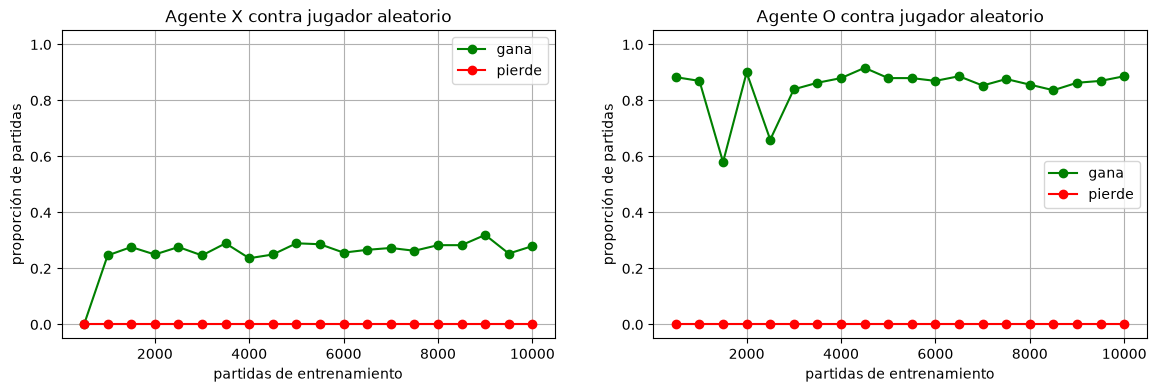

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, lado in zip(axs, ['X', 'O']):
    ax.plot(curva.index, curva[f'{lado} gana'], 'g-o', label='gana')
    ax.plot(curva.index, curva[f'{lado} pierde'], 'r-o', label='pierde')
    ax.set_title(f'Agente {lado} contra jugador aleatorio')
    ax.set_xlabel('partidas de entrenamiento')
    ax.set_ylabel('proporción de partidas')
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True)
    ax.legend()
plt.show()

## 6. La función de valor aprendida

Igual que en clase, la muestro ordenada de mayor a menor valor. Para que se entienda, la columna `tablero` escribe los 5 puntos en orden (1, 2, 3, 4, 5) con `X`, `O` y `·` para el vacío.

- Valor cerca de **1**: después de dejar esa posición, el agente casi siempre gana.
- Valor cerca de **0.5**: la partida suele terminar en empate.
- Valor cerca de **0**: esa jugada lleva a perder; el agente aprendió a **evitarla**.

In [11]:
def tablero_legible(clave):
    numeros = [int(float(v)) for v in clave.strip('[]').split()]
    return ''.join({1: 'X', -1: 'O', 0: '·'}[n] for n in numeros)


def tabla_valores(agente):
    filas = sorted(agente.value_function.items(), key=lambda kv: kv[1], reverse=True)
    return pd.DataFrame({'estado': [k for k, _ in filas],
                         'tablero (1 2 3 4 5)': [tablero_legible(k) for k, _ in filas],
                         'valor': [round(v, 3) for _, v in filas]})


tabla_x = tabla_valores(agente_x)
tabla_x

,estado,tablero (1 2 3 4 5),valor
0,[ 0 -1 1 1 -1],·OXXO,1.000
1,[-1 0 1 -1 1],O·XOX,1.000
2,[-1 1 1 0 -1],OXX·O,0.683
3,[ 0 1 -1 1 -1],·XOXO,0.619
4,[ 1 -1 1 -1 0],XOXO·,0.617
5,[ 1 1 0 -1 -1],XX·OO,0.561
6,[-1 1 -1 1 0],OXOX·,0.560
7,[-1 -1 0 1 1],OO·XX,0.541
8,[ 1 -1 -1 0 1],XOO·X,0.528
9,[ 1 0 -1 -1 1],X·OOX,0.526


In [12]:
tabla_o = tabla_valores(agente_o)
tabla_o

,estado,tablero (1 2 3 4 5),valor
0,[ 1 0 -1 1 -1],X·OXO,1.000
1,[ 0 1 -1 -1 1],·XOOX,1.000
2,[ 1 -1 -1 0 1],XOO·X,0.668
3,[-1 1 -1 1 0],OXOX·,0.637
4,[-1 1 1 0 -1],OXX·O,0.630
5,[-1 0 1 1 -1],O·XXO,0.625
6,[ 1 -1 1 -1 0],XOXO·,0.621
7,[-1 -1 0 1 1],OO·XX,0.600
8,[ 0 -1 1 -1 1],·OXOX,0.599
9,[ 1 1 0 -1 -1],XX·OO,0.596


**Ejemplos de lo que aprendió el agente X:**
- `·OXXO` tiene valor **1.0**: el vacío está en el punto 1 y solo se llega a él desde 3 o 4, que son de X. A O le toca y **no puede mover**: X ganó.
- `OX·OX` tiene valor **0.03** (el más bajo): X dejó el centro libre y O puede mover de 1 a 3. Queda `·XOOX`: el vacío en 1 solo se alcanza desde 3 y 4, que ahora son de O, y **X queda bloqueado**. El agente aprendió a no dejar nunca esa posición.
- Las posiciones con valor cercano a 0.5 son las "neutrales", que normalmente terminan en empate.

## 7. Evaluación final

Comparo con la línea base, jugando 2000 partidas sin exploración:

In [13]:
final = pd.DataFrame({
    'Aleatorio como X': linea_base.loc['Aleatorio como X'],
    'Agente X entrenado': evaluar(agente_x, Aleatorio(), 1, partidas=2000),
    'Aleatorio como O': linea_base.loc['Aleatorio como O'],
    'Agente O entrenado': evaluar(agente_o, Aleatorio(), -1, partidas=2000),
}).T
final

,gana,empata,pierde
Aleatorio como X,0.1770,0.5310,0.292
Agente X entrenado,0.2645,0.7355,0.000
Aleatorio como O,0.2770,0.5450,0.178
Agente O entrenado,0.8715,0.1285,0.000


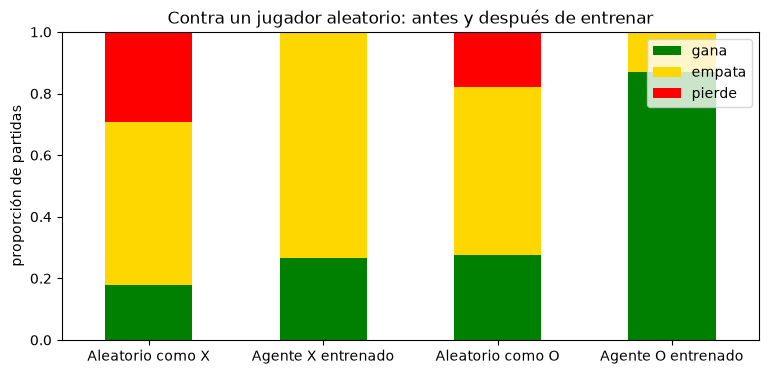

Agente X contra agente O (los dos entrenados): {'gana': 0.0, 'empata': 1.0, 'pierde': 0.0}


In [14]:
final[['gana', 'empata', 'pierde']].plot(kind='bar', stacked=True, color=['green', 'gold', 'red'], figsize=(9, 4), rot=0)
plt.ylabel('proporción de partidas')
plt.title('Contra un jugador aleatorio: antes y después de entrenar')
plt.legend(loc='upper right')
plt.show()

print('Agente X contra agente O (los dos entrenados):', evaluar(agente_x, agente_o, 1, partidas=100))

**Lectura de los resultados:**
- Los dos agentes entrenados **nunca pierden** contra el jugador aleatorio (0%), mientras que jugando al azar se perdía el 29% (como X) y el 18% (como O), y el agente sin entrenar perdía ~57-59%.
- El agente O gana mucho más que el agente X. Esto no es un error: en este juego **el que empieza tiene menos oportunidades de encerrar al rival** (ya se ve en la línea base: al azar, X pierde más que O). El agente X aprende sobre todo a **no caer en trampas** y a ganar cuando el rival se equivoca.
- Cuando los dos agentes entrenados juegan entre sí, **siempre empatan**: ninguno deja una posición donde pueda ser encerrado. Esto coincide con lo que se sabe del Pong Hau K'i: con juego perfecto de ambos lados, nadie gana.

## 8. Partida de demostración: agente X contra un jugador aleatorio

In [15]:
np.random.seed(2)
agente_x.symbol = 1
rival = Aleatorio()
rival.symbol = -1
board = Board()
dibujar_tablero(board)
while board.is_game_over() is None:
    actual = agente_x if board.turno == 1 else rival
    origen, destino = actual.move(board, explore=False)
    board.update(actual.symbol, origen, destino)
    print(f"{'Agente X' if actual is agente_x else 'Aleatorio O'} mueve {origen + 1} -> {destino + 1}")
    dibujar_tablero(board)

ganador = board.is_game_over()
print({1: 'Gana el agente X', -1: 'Gana el aleatorio O', 0: 'Empate'}[ganador])

 X(1)         X(2)
  |  \       /  |
  |    \   /    |
  |     ·(3)    |
  |    /   \    |
  |  /       \  |
 O(4)---------O(5)

Agente X mueve 2 -> 3
 X(1)         ·(2)
  |  \       /  |
  |    \   /    |
  |     X(3)    |
  |    /   \    |
  |  /       \  |
 O(4)---------O(5)

Aleatorio O mueve 5 -> 2
 X(1)         O(2)
  |  \       /  |
  |    \   /    |
  |     X(3)    |
  |    /   \    |
  |  /       \  |
 O(4)---------·(5)

Agente X mueve 3 -> 5
 X(1)         O(2)
  |  \       /  |
  |    \   /    |
  |     ·(3)    |
  |    /   \    |
  |  /       \  |
 O(4)---------X(5)

Aleatorio O mueve 2 -> 3
 X(1)         ·(2)
  |  \       /  |
  |    \   /    |
  |     O(3)    |
  |    /   \    |
  |  /       \  |
 O(4)---------X(5)

Agente X mueve 5 -> 2
 X(1)         X(2)
  |  \       /  |
  |    \   /    |
  |     O(3)    |
  |    /   \    |
  |  /       \  |
 O(4)---------·(5)

Aleatorio O mueve 4 -> 5
 X(1)         X(2)
  |  \       /  |
  |    \   /    |
  |     O(3)    |
  |    /   \

## 9. Guardar el agente

Igual que en clase, guardo las funciones de valor con `pickle` para poder jugar sin volver a entrenar.

In [16]:
with open('modelos/agente_pong_hau_ki.pickle', 'wb') as handle:
    pickle.dump({'X': agente_x.value_function, 'O': agente_o.value_function}, handle, protocol=pickle.HIGHEST_PROTOCOL)

with open('modelos/agente_pong_hau_ki.pickle', 'rb') as handle:
    funciones_de_valor = pickle.load(handle)
print({lado: len(tabla) for lado, tabla in funciones_de_valor.items()})

{'X': 28, 'O': 28}


## 10. Jugar contra el agente (humano vs agente)

Igual que el cuadernillo `tres.ipynb` de clase. Tú eliges **qué ficha mover** (el número del punto, 1 a 5); el destino siempre es el punto vacío. Ejecuta la última celda para jugar: con `agente_empieza=True` el agente es X y tú O; con `False` empiezas tú con X.

In [17]:
class AgentInferencia():
    def __init__(self, value_function, symbol):
        self.value_function = value_function
        self.symbol = symbol

    def move(self, board, explore=False):
        max_value = -1000
        for origen, destino in board.valid_moves(self.symbol):
            next_board = board.state.copy()
            next_board[destino] = self.symbol
            next_board[origen] = 0
            value = self.value_function.get(str(next_board), 0)
            if value >= max_value:
                max_value = value
                mejor = (origen, destino)
        return mejor


def movimiento_humano(board, simbolo):
    jugadas = {origen + 1: (origen, destino) for origen, destino in board.valid_moves(simbolo)}
    while True:
        entrada = input(f'Tu turno: ¿qué ficha mueves? {sorted(jugadas)}: ').strip()
        if entrada.isdigit() and int(entrada) in jugadas:
            return jugadas[int(entrada)]
        print('Esa ficha no se puede mover.')


def jugar(agente_empieza=True):
    simbolo_agente = 1 if agente_empieza else -1
    simbolo_humano = -simbolo_agente
    agente = AgentInferencia(funciones_de_valor['X' if agente_empieza else 'O'], simbolo_agente)
    print(f"Agente: {'X' if agente_empieza else 'O'} | Humano: {'O' if agente_empieza else 'X'}")
    board = Board()
    dibujar_tablero(board)
    while board.is_game_over() is None:
        if board.turno == simbolo_agente:
            origen, destino = agente.move(board)
            print(f'El agente mueve {origen + 1} -> {destino + 1}')
        else:
            origen, destino = movimiento_humano(board, simbolo_humano)
        board.update(board.turno, origen, destino)
        dibujar_tablero(board)
    ganador = board.is_game_over()
    if ganador == simbolo_agente:
        print('Gana el agente.')
    elif ganador == simbolo_humano:
        print('Ganaste.')
    else:
        print('Empate (20 movimientos).')

In [ ]:
jugar(agente_empieza=True)

## 11. Conclusiones (para la defensa)

- **Qué se hizo:** se programó el juego Pong Hau K'i y dos agentes que aprenden a jugarlo solo jugando entre ellos, sin que nadie les diga qué jugada es buena. Lo único que reciben es la recompensa al final de la partida.
- **Por qué funciona:** el agente guarda un valor para cada posición que deja en el tablero. Al terminar, el resultado (1, 0.5 o 0) se reparte hacia atrás entre las posiciones de esa partida. Después de miles de partidas, las posiciones que llevan a ganar tienen valor alto y las que llevan a perder, valor bajo; el agente simplemente elige la jugada que lleva a la posición de mayor valor.
- **Exploración:** si el agente siempre eligiera la mejor jugada conocida, nunca probaría otras y podría quedarse con una estrategia mala. Con `prob_exp = 0.5` juega al azar la mitad de las veces durante el entrenamiento y así visita casi todas las posiciones (cada agente aprendió el valor de 28 de las 30 posibles).
- **Resultado:** contra un rival aleatorio, jugar al azar pierde 18-29% de las partidas y el agente sin entrenar ~58%; después de entrenar, **0%**. Además el agente O gana el 87% de las partidas y el X el 26% (el resto, empates). Entre los dos agentes entrenados, siempre empate, que es el resultado del juego perfecto.
- **Por qué es simple:** no se usan redes neuronales ni técnicas avanzadas; es una tabla (diccionario) con 30 filas como máximo y la misma regla de actualización del tres en raya visto en clase.